# Чи можна передбачити переможця скачок? Модель проти ринку ставок

**Курс:** Machine Learning, НаУКМА · **Міні-проєкт** · дані: Kaggle `hwaitt/horse-racing` (Великобританія та Ірландія, 1990–2020)

**Коротко.** Для кожного коня в кожному забігу ми оцінюємо ймовірність перемоги за інформацією, відомою до старту,
і перевіряємо, чи така оцінка краща за ймовірності, які неявно містяться в ринкових коефіцієнтах.
Валідація йде за часом (навчання 2005–2016, перевірка 2017–2018, фінальний тест 2019), а всі висновки подано з довірчими
інтервалами. Головні числа зведено в розділі 13.

## 1. Постановка задачі

**Питання.** Чи можна за ознаками, відомими *до старту* забігу (характеристики коня, жокей, тренер, умови забігу),
передбачити переможця і чи додає така модель інформацію *понад* ринкову ціну?

**Чому це важливо.** Ринок ставок агрегує думку тисяч учасників, тому це жорсткий еталон. Якщо модель на публічних ознаках його не обходить,
це свідчення ефективності ринку, а якщо обходить, то це знахідка, яку варто перевіряти на витік і на стійкість. Обидва результати змістовні.

**Одиниця спостереження:** кінь у забігу. **Ціль:** `res_win` (1, якщо кінь переміг). Приблизно 10% рядків позитивні, у кожному забігу рівно один переможець.

**Два експерименти.**
- **A (без ринку):** лише характеристики коня й забігу та історична форма коня, жокея й тренера. Питання: скільки можна передбачити без цінової інформації.
- **B (з ринком):** ті самі ознаки плюс ринкова ймовірність. Питання: чи додає модель щось до ринку.

**Критерій відповіді.** Модель «додає» до ринку, якщо 95% довірчий інтервал парної різниці за log-loss лежить цілком в області покращення відносно
**ринку з перекалібруванням** (логістична регресія на логіті ринкової ймовірності, baseline 4 з розділу 8), а не лише відносно сирого ринку.
Причина: частину виграшу може давати саме виправлення систематичного зсуву ринкових ймовірностей, а це не нова інформація про коней.
Сирий ринок лишаємо другим орієнтиром. Частка вгаданих переможців (top-1) розглядається як друга, більш груба, перевірка.
Обґрунтування метрик наведено в розділі 8.

## 0. Налаштування


### Налаштування середовища

Код проєкту винесено в пакет `src/horses` (дані, історичні ознаки, метрики, моделі, графіки), а в ноутбуці лишаються
постановка, аналіз і результати. Ноутбук можна запускати з будь-якої папки репозиторію: корінь шукається автоматично.
Дані очікуються в `data/merged.parquet` (результат `scripts/merge_data.py`).

| Модуль | Призначення |
|---|---|
| `config.py` | шляхи, seed, роки розбиття, списки ознак |
| `data.py` | відбір рядків, чищення, модельна таблиця, розбиття за роками |
| `history.py` | історичні ознаки без витоку й тест на витік |
| `evaluation.py` | метрики рівня забігу, bootstrap по забігах, парні порівняння |
| `baselines.py` | constant, випадковий вибір, ринок, ринок з перекалібруванням |
| `models.py` | пайплайни LogReg, Random Forest, LightGBM |
| `plots.py`, `analysis.py` | графіки, сегменти помилок, важливість ознак |
| `reporting.py` | текстові висновки, що рахуються з результатів |


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "horses").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from horses import config as cfg
from horses.baselines import baseline_scores, fit_market_recalibrator
from horses.data import add_clean_features, make_model_table, select_modelling_rows, split_by_year
from horses.evaluation import bootstrap, ci, metrics_row, paired, score, summary_table
from horses.history import add_history_features, leak_test, load_history_source

SEED = cfg.SEED
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

TARGET = cfg.TARGET
NUM_FEATURES, CAT_FEATURES, FLAG_FEATURES, MARKET = cfg.NUM_FEATURES, cfg.CAT_FEATURES, cfg.FLAG_FEATURES, cfg.MARKET
HIST_FEATURES = cfg.HIST_FEATURES
FIG = cfg.FIG_DIR
FIG.mkdir(exist_ok=True)

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)
df = pd.read_parquet(cfg.MERGED_PATH)
print(df.shape)

python 3.14.7 | pandas 3.0.5 | numpy 2.5.3
(4107315, 47)


## 2. Дані: структура та якість

Дані складаються з 31 пари файлів (`horses_YYYY.csv`, `races_YYYY.csv`), які з'єднуються за ключем `rid` (багато коней до одного забігу).
Файл `forward.csv` не використовується: це майбутні забіги без результатів.

In [2]:
print("Розмір:", df.shape)
print("Пам'ять, МБ:", round(df.memory_usage(deep=True).sum() / 1e6))
print()
df.info(show_counts=True)

Розмір: (4107315, 47)
Пам'ять, МБ: 2368

<class 'pandas.DataFrame'>
RangeIndex: 4107315 entries, 0 to 4107314
Data columns (total 47 columns):
 #   Column        Non-Null Count    Dtype  
---  ------        --------------    -----  
 0   rid           4107315 non-null  int64  
 1   horseName     4107315 non-null  str    
 2   age           4107006 non-null  float64
 3   saddle        3928147 non-null  float64
 4   decimalPrice  4107315 non-null  float64
 5   isFav         4107315 non-null  int64  
 6   trainerName   4104465 non-null  str    
 7   jockeyName    4107190 non-null  str    
 8   position      4107315 non-null  int64  
 9   positionL     3323653 non-null  str    
 10  dist          3032930 non-null  str    
 11  weightSt      4107315 non-null  int64  
 12  weightLb      4107315 non-null  int64  
 13  overWeight    94327 non-null    float64
 14  outHandicap   112983 non-null   float64
 15  headGear      987620 non-null   str    
 16  RPR           3242438 non-null  float64
 1

In [3]:
print("Кількість колонок за типами:")
print(df.dtypes.astype(str).value_counts().to_string())

print("\nДублікатів (rid, horseName):", df.duplicated(subset=["rid", "horseName"]).sum())

Кількість колонок за типами:
str        23
float64    14
int64       9
string      1

Дублікатів (rid, horseName): 0


**Результат об'єднання.** 4 107 315 рядків × 47 колонок, 395 186 забігів. Жоден рядок не втрачено, осиротілих рядків немає, дублікатів пари (забіг, кінь) немає.
1 386 забігів з `races` не мали жодного коня в `horses` і випали при inner join; це слід вказати як обмеження.
У пам'яті таблиця займає ≈ 2,4 ГБ, тому далі обмежуємо роки й колонки (розділ 6).

**Типи.** 23 текстові, 14 дробових, 9 цілих колонок і `ncond` (змішаний тип, приведений до тексту ще в `merge.py`).

In [4]:
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
rid,4107315.0,207919.066,119929.009,0.000,103602.500,208634.000,311756.000,4.150900e+05
age,4107006.0,4.914,2.246,-17.000,3.000,4.000,6.000,2.700000e+01
saddle,3928147.0,5.903,4.809,0.000,2.000,5.000,9.000,4.000000e+01
decimalPrice,4107315.0,0.118,0.114,0.001,0.038,0.077,0.154,9.900000e-01
isFav,4107315.0,0.104,0.306,0.000,0.000,0.000,0.000,1.000000e+00
position,4107315.0,8.533,9.465,0.000,3.000,6.000,10.000,4.000000e+01
weightSt,4107315.0,9.238,1.159,0.000,8.000,9.000,10.000,2.000000e+01
weightLb,4107315.0,6.141,4.154,0.000,2.000,6.000,10.000,1.300000e+01
overWeight,94327.0,2.219,2.014,1.000,1.000,2.000,3.000,6.000000e+01
outHandicap,112983.0,5.526,5.985,-8.000,1.000,4.000,7.000,1.380000e+02


In [5]:
display(df.select_dtypes(exclude="number").describe().T)

,count,unique,top,freq
horseName,4107315,371869,Dvinsky,230
trainerName,4104465,18448,Mark Johnston,30685
jockeyName,4107190,17721,Joe Fanning,21646
positionL,3323653,261,.5,244110
dist,3032930,1183,4.5,44930
headGear,987620,40,b,353274
father,4106026,11040,Presenting,20275
mother,4102835,158818,Silk St James,529
gfather,3987941,11194,Sadler's Wells,41840
price,95011,578,12/1,3392


**Аномалії в числових колонках**, які вимагають чищення:

| Колонка | Проблема |
|---|---|
| `age` | значення від −17 до 27 (неможливо для коня) |
| `saddle`, `weightSt` | нулі, які є заглушками замість пропуску |
| `position` | значення 1–14 і службовий код **40** (≈ 7% рядків) |
| `overWeight`, `outHandicap` | заповнені менш ніж у 3% рядків |
| `decimalPrice` | діапазон 0,001–0,99: за змістом ймовірність, а не коефіцієнт (див. розділ 3) |

**Категоріальні колонки** мають дуже різну кардинальність: `horseName` ≈ 372 тис., `mother` ≈ 159 тис., `trainerName` ≈ 18,4 тис., `jockeyName` ≈ 17,7 тис., `course` 440.
One-hot для коня, жокея й тренера неможливий, тому для них будуються історичні ознаки (розділ 9).

### 2.1. Цільова змінна

In [6]:
y = df["res_win"]
print(y.value_counts(dropna=False).to_string())
print("\nчастка перемог:", round(y.mean(), 4))

print("\nposition == 1 проти res_win:")
display(pd.crosstab(df["position"] == 1, df["res_win"], dropna=False))

print("position, найчастіші значення:")
print(df["position"].value_counts().head(15).sort_index().to_string())

res_win
0.0    3711478
1.0     395837

частка перемог: 0.0964

position == 1 проти res_win:


res_win,0.0,1.0
position,,
False,3711478,0
True,0,395837


position, найчастіші значення:
position
1     395837
2     395209
3     393226
4     385115
5     365321
6     336301
7     300659
8     261790
9     222595
10    185769
11    148773
12    118563
13     89805
14     67504
40    284261


In [7]:
wins_per_race = df.groupby("rid")["res_win"].sum()
print("Переможців на забіг:")
print(wins_per_race.value_counts().sort_index().to_string())

rows_per_race = df.groupby("rid").size()
runners = df.groupby("rid")["runners"].first()
print("\nrunners == кількість рядків у забігу:", round((rows_per_race == runners).mean(), 4))

random_baseline = (1 / rows_per_race).mean()
print("Випадковий вибір (середнє 1/N по забігах):", round(random_baseline, 4))

Переможців на забіг:
res_win
0.0         2
1.0    394531
2.0       653

runners == кількість рядків у забігу: 1.0
Випадковий вибір (середнє 1/N по забігах): 0.1144


Пропусків у `res_win` немає. Частка перемог по рядках **9,64%**. `res_win` збігається з `position == 1` без жодного винятку.
У 394 531 забігу рівно один переможець, у 653 два (мертва гонка), у 2 жодного; ці 655 забігів (0,17%) виключаємо як неоднозначні.
Поле `runners` збігається з кількістю рядків у 100% забігів, тобто забіги в `horses` повні.

**Орієнтири.** Випадковий вибір коня в забігу вгадує переможця з імовірністю 1/N; усереднене по забігах це **11,44%** (по рядках 9,64%, бо у великих забігах більше рядків).
Через дисбаланс класів accuracy не інформативна: модель «ніхто не виграє» має ≈ 90%.

### 2.2. Пропуски

In [8]:
nan_total = df.isna().mean().sort_values(ascending=False)
display(nan_total[nan_total > 0].round(3).to_frame("частка NaN"))

,частка NaN
overWeight,0.977
currency,0.977
price,0.977
outHandicap,0.972
headGear,0.760
hurdles,0.701
band,0.579
OR,0.437
rclass,0.418
TR,0.409


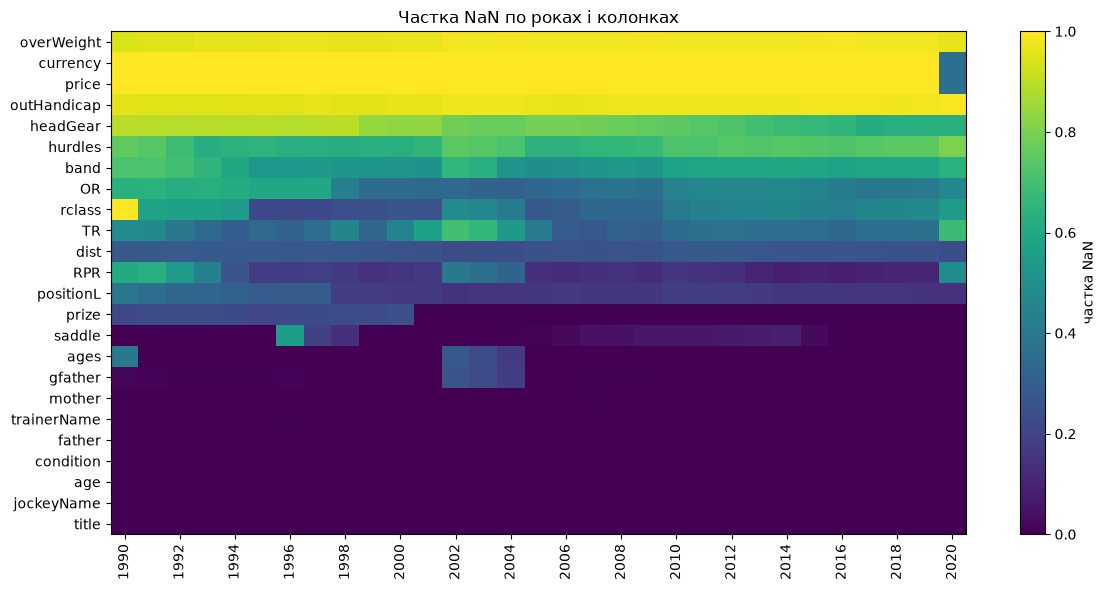

year,1990,1995,2000,2005,2010,2015,2020
overWeight,0.94,0.96,0.97,0.98,0.98,0.99,0.97
currency,1.00,1.00,1.00,1.00,1.00,1.00,0.36
price,1.00,1.00,1.00,1.00,1.00,1.00,0.36
outHandicap,0.96,0.96,0.96,0.97,0.98,0.98,0.99
headGear,0.90,0.89,0.83,0.79,0.75,0.67,0.63
hurdles,0.75,0.65,0.63,0.64,0.72,0.73,0.80
band,0.72,0.53,0.52,0.50,0.58,0.59,0.64
OR,0.64,0.60,0.35,0.34,0.44,0.45,0.47
rclass,1.00,0.22,0.26,0.28,0.42,0.44,0.55
TR,0.48,0.34,0.45,0.42,0.35,0.36,0.68


In [9]:
nan_by_year = df.drop(columns=["year"]).isna().groupby(df["year"]).mean()
cols = nan_total[nan_total > 0].index

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(nan_by_year[cols].T.values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)
ax.set_xticks(range(0, len(nan_by_year), 2))
ax.set_xticklabels(nan_by_year.index[::2], rotation=90)
ax.set_title("Частка NaN по роках і колонках")
fig.colorbar(im, ax=ax, label="частка NaN")
fig.tight_layout()
fig.savefig(FIG / "nan_by_year.png", dpi=150)
plt.show()

display(nan_by_year.loc[[1990, 1995, 2000, 2005, 2010, 2015, 2020], cols].T.round(2))

,rows,races,win_rate,mean_runners
year,,,,
1990,88195,8718,0.099,12.379
1991,89693,8508,0.095,12.651
1992,90152,8692,0.097,12.399
1993,90311,8819,0.098,12.382
1994,91738,8788,0.096,12.495
1995,87167,8813,0.101,12.047
1996,93553,9071,0.097,12.275
1997,94501,9246,0.098,12.280
1998,100431,9320,0.093,12.810


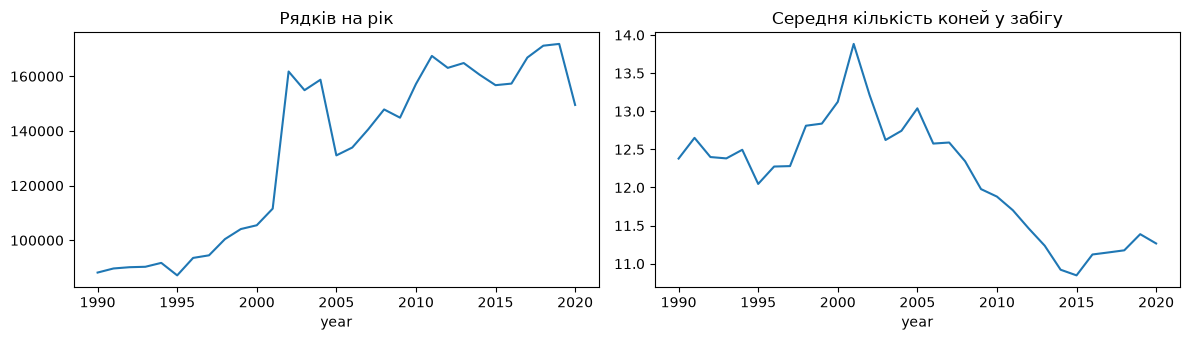

In [10]:
per_year = df.groupby("year").agg(rows=("rid", "size"), races=("rid", "nunique"),
                                  win_rate=("res_win", "mean"), mean_runners=("runners", "mean"))
display(per_year.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
per_year["rows"].plot(ax=axes[0], title="Рядків на рік")
per_year["mean_runners"].plot(ax=axes[1], title="Середня кількість коней у забігу")
fig.tight_layout()
fig.savefig(FIG / "rows_per_year.png", dpi=150)
plt.show()

Загалом майже порожні `overWeight`, `outHandicap`, `price`, `currency` (97–98% NaN). Помірно заповнені `headGear` (76% NaN), `hurdles` (70%), `band` (58%), `OR` (44%), `rclass` (42%), `TR` (41%).

Розбивка за роками показує, що пропуски залежать від епохи:
- `price` і `currency` з'являються лише у 2020 (нова схема даних);
- `rclass` порожня на 100% у 1990 році; `prize` має ≈ 22–24% пропусків до 2000 року і **жодного з 2005**;
- частка NaN у `headGear` падає з 0,90 (1990) до 0,63 (2020): у ранні роки пропуск частково означає «не записано», а не «без спорядження»;
- `RPR` і `TR` у 2020 мають значно більше пропусків (0,48 і 0,68), що узгоджується з пізнішим заповненням рейтингів.

Обсяг даних також змінюється: стрибок з 111 583 рядків (2001) до 161 752 (2002) і спад до 131 060 (2005). Базова частка перемог дрейфує
від 0,084 (2001) до 0,106 (2014), бо поля меншають (середньо 13,9 → 10,8 коня). 2020 рік неповний (дані до 15 червня) і має іншу схему.

**Наслідки:** (1) беремо роки з 2005; (2) валідація має бути за часом через дрейф базового рівня.

## 3. Аудит витоку інформації

Витік (leakage) виникає, коли в ознаках міститься інформація, недоступна до старту, зокрема результат забігу. Він найнебезпечніший для висновків: модель із витоком показує вигадану точність.
Тому кожну колонку класифікуємо за гіпотезою «відома до старту / після» і перевіряємо гіпотезу на даних.

In [11]:
hypothesis = {
    "target":       ["res_win"],
    "post_race":    ["position", "positionL", "dist", "res_place", "winningTime"],
    "suspicious":   ["RPR", "TR"],   
    "market":       ["decimalPrice", "isFav", "price", "margin"],  
    "pre_race":     ["age", "saddle", "weightSt", "weightLb", "weight", "overWeight",
                     "outHandicap", "headGear", "OR", "runners", "trainerName", "jockeyName",
                     "father", "mother", "gfather", "horseName"],
    "race_context": ["course", "time", "date", "title", "rclass", "band", "ages", "distance",
                     "condition", "hurdles", "prizes", "prize", "countryCode", "ncond",
                     "class", "currency", "year", "rid", "metric"],   
}
known = {c for v in hypothesis.values() for c in v}
print("Колонки без гіпотези:", [c for c in df.columns if c not in known])
print("Гіпотези для відсутніх колонок:", [c for c in known if c not in df.columns])

Колонки без гіпотези: []
Гіпотези для відсутніх колонок: []


Усі 47 колонок мають гіпотезу. Гіпотези ґрунтуються на назвах і перших рядках, тому нижче перевіряємо їх емпірично.

**Емпірична перевірка.** Для ознаки беремо в кожному забігу коня з найбільшим значенням і дивимось, як часто він переможець (hit rate).
Для чесної передстартової ознаки очікуємо рівень порядку ринкового фаворита (≈ 0,33–0,35), для ознаки з витоком значно більше.
Перша версія перевірки (нижче) має методологічну похибку, яку виявляє й виправляє друга.

In [12]:
def hit_rate(feature, higher_is_better=True):
    """Як часто кінь з найкращим значенням ознаки в забігу є переможцем."""
    sub = df[["rid", feature, "res_win"]].dropna(subset=[feature])
    idx = (sub.groupby("rid")[feature].idxmax() if higher_is_better
           else sub.groupby("rid")[feature].idxmin())
    return sub.loc[idx, "res_win"].mean(), len(idx)

rows = []
for f, hib in [("decimalPrice", True), ("RPR", True), ("TR", True), ("OR", True),
               ("weight", True), ("age", True), ("saddle", False), ("metric", True)]:
    r, n = hit_rate(f, hib)
    rows.append({"feature": f, "top_horse_win_rate": round(r, 3), "races_used": n})

audit = pd.DataFrame(rows)
print("Випадковий вибір ≈", round(random_baseline, 3))
display(audit)

Випадковий вибір ≈ 0.114


,feature,top_horse_win_rate,races_used
0,decimalPrice,0.353,395186
1,RPR,0.705,366177
2,TR,0.703,298167
3,OR,0.214,264342
4,weight,0.351,395186
5,age,0.378,395186
6,saddle,0.274,376625
7,metric,0.997,395186


**Похибка першої версії.** `idxmax()` при рівних значеннях повертає перший рядок групи, а рядки всередині кожного забігу **впорядковані за фінішною позицією**
(перший рядок є переможцем у 99,75% забігів, див. нижче). Тому нічиї в значенні ознаки автоматично діставалися переможцю: hit rate був завищений
самим порядком рядків. Особливо це видно в `age` (0,378 проти справжніх 0,094) і `weight` (0,351 проти 0,161), тобто вік «вгадував» переможця краще за ринок, що неможливо.

**Наслідок для всього проєкту:** порядок рядків у файлі сам є витоком, тому рядки перемішуються перед будь-яким навчанням (розділ 6), а нічиї розв'язуються випадково.
У виправленій версії рядки перемішуються перед вибором максимуму.

In [13]:
first_pos = df.groupby("rid")["position"].first()
print("Забігів, де ПЕРШИЙ рядок = переможець:", round((first_pos == 1).mean(), 4))

check_cols = ["metric", "winningTime", "margin", "prize", "runners",
              "decimalPrice", "weight", "age", "saddle", "OR"]
within = {c: round(df.groupby("rid")[c].nunique().gt(1).mean(), 3) for c in check_cols}
print("\nЧастка забігів, де колонка МІНЯЄТЬСЯ між кіньми:")
print(pd.Series(within).to_string())

Забігів, де ПЕРШИЙ рядок = переможець: 0.9975

Частка забігів, де колонка МІНЯЄТЬСЯ між кіньми:
metric          0.000
winningTime     0.000
margin          0.000
prize           0.000
runners         0.000
decimalPrice    1.000
weight          0.957
age             0.721
saddle          0.817
OR              0.629


In [14]:
def hit_rate_fair(feature, higher_is_better=True):
    sub = (df[["rid", feature, "res_win"]]
           .dropna(subset=[feature])
           .sample(frac=1, random_state=SEED))         
    g = sub.groupby("rid")[feature]
    idx = g.idxmax() if higher_is_better else g.idxmin()
    return sub.loc[idx, "res_win"].mean(), len(idx)

rows = []
for f, hib in [("decimalPrice", True), ("RPR", True), ("TR", True), ("OR", True),
               ("weight", True), ("age", True), ("saddle", False)]:
    r, n = hit_rate_fair(f, hib)
    rows.append({"feature": f, "hit_rate_v2": round(r, 3), "races_used": n})

audit_v2 = pd.DataFrame(rows).merge(audit[["feature", "top_horse_win_rate"]], on="feature", how="left")
audit_v2 = audit_v2.rename(columns={"top_horse_win_rate": "hit_rate_v1"})
audit_v2["inflation_by_order"] = (audit_v2["hit_rate_v1"] - audit_v2["hit_rate_v2"]).round(3)
print("Випадковий вибір ≈", round(random_baseline, 3))
display(audit_v2)

Випадковий вибір ≈ 0.114


,feature,hit_rate_v2,races_used,hit_rate_v1,inflation_by_order
0,decimalPrice,0.334,395186,0.353,0.019
1,RPR,0.677,366177,0.705,0.028
2,TR,0.676,298167,0.703,0.027
3,OR,0.184,264342,0.214,0.030
4,weight,0.161,395186,0.351,0.190
5,age,0.094,395186,0.378,0.284
6,saddle,0.148,376625,0.274,0.126


**Результат виправленої перевірки** (випадковий вибір ≈ 0,114):

| Ознака | hit rate | Висновок |
|---|---|---|
| `decimalPrice` (ринок) | 0,334 | еталон чесної ознаки |
| `RPR`, `TR` | 0,677 / 0,676 | майже вдвічі вище за ринок; завищення порядком мале (≈ 0,03), тож це справжній витік: рейтинги виставляють за виступ у цьому забігу |
| `OR` | 0,184 | передстартовий офіційний рейтинг, помірний сигнал |
| `saddle` (найменший номер) | 0,148 | слабкий сигнал |
| `weight` | 0,161 | слабкий сигнал |
| `age` | 0,094 | нижче за випадковий: старші коні виграють рідше |

`RPR` і `TR` виключаємо. Колонки `metric`, `winningTime`, `margin`, `prize`, `runners` однакові в усіх коней забігу (характеристики забігу, а не коня), тому для вибору серед коней самі по собі нічого не дають.

### 3.1. Дві колонки, які були класифіковані хибно

У попередній гіпотезі `metric` та `margin` були записані як постфактумні. Дані цьому суперечать:
- `metric` для `3m1f` дорівнює 5028 = 3 × 1609 + 1 × 201, тобто це **дистанція забігу в метрах** (миля = 1609 м, фарлонг = 201 м). Вона відома до старту і не має пропусків.
  Це корисно: розбір текстової колонки `distance` давав 21% пропусків (нестандартні формати), а `metric` заповнена повністю.
- `margin` має максимум 3,944, що збігається з максимальною сумою `decimalPrice` по забігу. Це **маржа букмекера** (сума неявних ймовірностей), а не відрив на фініші.
  Вона похідна від ринкових цін, тому в експеримент A не входить, а в B нічого не додає до нормованої ринкової ймовірності.

**Перевірка на даних.** Для 79,5% забігів текстову дистанцію вдалося розібрати, і в **усіх** них `metric` збігається з 1609 × милі + 201 × фарлонги + ярди в межах 5 м (медіана розбіжності 0 м). Решта 20,5% забігів мають дистанції на кшталт `2m4½f` (півфарлонги), які простий розбір не розуміє, тому `metric` також надійніша за текст. Колонка не має пропусків (804–7340 м). `margin` збігається із сумою `decimalPrice` по забігу в більшості забігів (медіана розбіжності 0, максимум 0,18). `winningTime` (час переможця) залишається постфактумною колонкою.

In [15]:
def metres_from_text(s):
    parts = s.str.extract(r"^(?:(\d+)m)?(?:(\d+)f)?(?:(\d+)y)?$")
    m, f, y = (pd.to_numeric(parts[i]).fillna(0) for i in range(3))
    return (m * 1609 + f * 201 + y * 0.9144).where(~parts.isna().all(axis=1))

one = df.drop_duplicates("rid")[["rid", "distance", "metric"]]
calc = metres_from_text(one["distance"])
ok = calc.notna()
err = (one.loc[ok, "metric"] - calc[ok]).abs()
print(f"Текстову дистанцію вдалося розібрати для {ok.mean():.1%} забігів")
print(f"|metric - (1609·милі + 201·фарлонги + ярди)|: медіана {err.median():.1f} м, збіг у межах 5 м: {(err <= 5).mean():.1%}")
print("Приклади нерозібраних форматів distance:", one.loc[~ok, "distance"].drop_duplicates().head(8).tolist())
print("metric: пропусків", int(one["metric"].isna().sum()), "| мін", one["metric"].min(), "| макс", one["metric"].max())

race_sum = df.groupby("rid")["decimalPrice"].sum()
race_margin = df.groupby("rid")["margin"].first()
diff = (race_margin - race_sum).abs()
print(f"\n|margin - сума decimalPrice по забігу|: максимум {diff.max():.6f}, медіана {diff.median():.6f}")

Текстову дистанцію вдалося розібрати для 79.5% забігів
|metric - (1609·милі + 201·фарлонги + ярди)|: медіана 0.0 м, збіг у межах 5 м: 100.0%
Приклади нерозібраних форматів distance: ['1m7½f', '3m1½f', '2m4½f', '3m½f', '3m2½f', '2m3½f', '2m½f', '2m5½f']
metric: пропусків 0 | мін 804.0 | макс 7340.5

|margin - сума decimalPrice по забігу|: максимум 0.183824, медіана 0.000000


In [16]:
print("isFav на забіг:")
print(df.groupby("rid")["isFav"].sum().value_counts().sort_index().head(8).to_string())

overround = df.groupby("rid")["decimalPrice"].sum()
print("\nСума decimalPrice по забігу (якщо це ймовірності, очікуємо ~1.0-1.3):")
print(overround.describe().round(3).to_string())

isFav на забіг:
isFav
0       365
1    364199
2     27553
3      2714
4       298
5        48
6         5
7         3

Сума decimalPrice по забігу (якщо це ймовірності, очікуємо ~1.0-1.3):
count    395186.000
mean          1.222
std           0.134
min           1.000
25%           1.140
50%           1.191
75%           1.259
max           3.944


### 3.2. Ринкові колонки

Сума `decimalPrice` по забігу має середнє 1,222, медіану 1,191 і мінімум 1,000: ніколи менше одиниці. Це ймовірності, що неявно випливають із коефіцієнтів (1 / десятковий коефіцієнт),
із маржею букмекера порядку 19–22%. Тому для порівняння ймовірностей ми **нормуємо** їх у межах забігу (сума = 1).

`isFav` неоднозначна: у 364 199 забігів рівно один фаворит, у 365 жодного, у 27 553 двоє і більше (спільні фаворити). Надійніше визначати фаворита за `decimalPrice`.

Ціна на старті відома до фінішу, тому не є витоком, але вона вбирає думку всього ринку. Саме тому експерименти A і B розділені.

## 4. Кореляції, категоріальні ознаки, дати

In [17]:
num_cols = df.select_dtypes("number").columns.drop(["rid", "year"])
sample = df[num_cols].sample(min(1_000_000, len(df)), random_state=SEED)

corr_target = sample.corrwith(sample["res_win"]).drop("res_win").sort_values(key=abs, ascending=False)
display(corr_target.round(3).to_frame("corr з res_win"))

,corr з res_win
res_place,0.537
decimalPrice,0.365
RPR,0.277
isFav,0.264
position,-0.260
TR,0.246
runners,-0.121
saddle,-0.082
margin,-0.073
OR,0.067


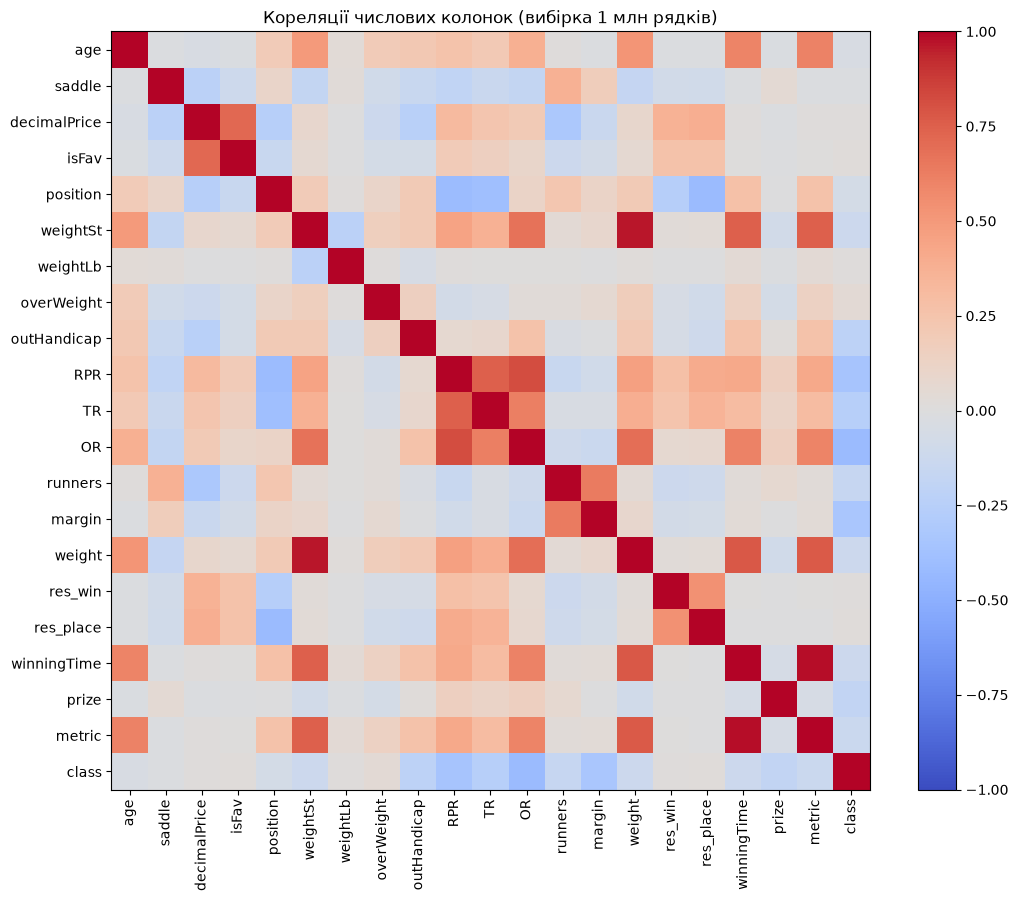

,a,b,corr
376,winningTime,metric,0.980318
119,weightSt,weight,0.967905


In [18]:
corr = sample.corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax)
ax.set_title("Кореляції числових колонок (вибірка 1 млн рядків)")
fig.tight_layout()
fig.savefig(FIG / "corr_heatmap.png", dpi=150)
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("corr").reset_index())
pairs.columns = ["a", "b", "corr"]
display(pairs[pairs["corr"].abs() > 0.9].sort_values("corr", key=abs, ascending=False))

**Кореляції з ціллю** (Пірсон, вибірка 1 млн рядків). Найвищі значення мають колонки з результатом: `res_place` (0,537) і `position` (−0,260).
Серед передстартових найсильніша `decimalPrice` (0,365), далі `isFav` (0,264). `RPR` (0,277) і `TR` (0,246) мають витік. Слабкі `runners` (−0,121; чим більше коней, тим менша імовірність кожного), `saddle` (−0,082), `OR` (0,067), `age` і `weight` близькі до нуля.
Кореляція Пірсона вловлює лише лінійний зв'язок по всіх рядках, тому майже нульова кореляція ваги чи віку не означає безкорисності: вони можуть діяти нелінійно або відносно суперників у забігу.

**Пари з |r| > 0,9:** `winningTime`–`metric` (0,98; довша дистанція дає довший час) і `weightSt`–`weight` (0,968; одна й та сама вага в різних одиницях).
Залишаємо `metric` (ознака) і замість обох ваг будуємо `weight_lb = стоуни × 14 + фунти`.

In [19]:
cat_cols = df.select_dtypes(exclude="number").columns
rows = []
for c in cat_cols:
    vc = df[c].value_counts(normalize=True, dropna=True)
    rows.append({"col": c, "nunique": df[c].nunique(), "top_value": vc.index[0] if len(vc) else None,
                 "top_share": round(vc.iloc[0], 3) if len(vc) else None})
display(pd.DataFrame(rows).sort_values("nunique", ascending=False))

const = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
print("Константні колонки:", const)

,col,nunique,top_value,top_share
0,horseName,371869,Dvinsky,0.000
13,title,237538,Irish Stallion Farms European Breeders Fund Fi...,0.001
7,mother,158818,Silk St James,0.000
20,prizes,54282,[],0.057
1,trainerName,18448,Mark Johnston,0.007
2,jockeyName,17721,Joe Fanning,0.005
8,gfather,11194,Sadler's Wells,0.010
6,father,11040,Presenting,0.005
12,date,11005,02/04/01,0.000
4,dist,1183,4.5,0.015


Константні колонки: []


Константних колонок немає. Висока кардинальність `horseName`, `title` (237 тис.), `mother`, `prizes`, `trainerName`, `jockeyName` виключає one-hot; `title` і `prizes` не використовуємо (їхню інформацію частково несуть `prize` і `rclass`).

In [20]:
d = pd.to_datetime(df["date"], format="%y/%m/%d", errors="coerce")
print("не розпарсилось:", d.isna().sum())
print("діапазон:", d.min(), "->", d.max())
print("рік з date == year:", round((d.dt.year == df["year"]).mean(), 4))

не розпарсилось: 95011
діапазон: 1990-01-01 00:00:00 -> 2020-06-15 00:00:00
рік з date == year: 0.9769


In [21]:
bad = d.isna()
print("Нерозпарсені дати за роками:")
print(df.loc[bad, "year"].value_counts().sort_index().to_string())
print("\nПриклади сирих значень:")
print(df.loc[bad, "date"].drop_duplicates().head(8).to_string())
print("\nУ нерозпарсених рядках `price` не порожня:", round(df.loc[bad, "price"].notna().mean(), 3))

Нерозпарсені дати за роками:
year
2020    95011

Приклади сирих значень:
4012304    20/06/16 00:00
4012923    20/06/17 00:00
4013581    20/06/18 00:00
4014164    20/06/19 00:00
4014824    20/06/20 00:00
4015557    20/06/21 00:00
4016311    20/06/22 00:00
4017033    20/06/23 00:00

У нерозпарсених рядках `price` не порожня: 1.0


**Дати.** 95 011 значень `date` не розпарсилось за форматом `рр/мм/дд`. Усі вони з 2020 року, мають інший формат (`рр/мм/дд гг:хх`) і збігаються з рядками, де заповнена `price`, тобто це рядки нової схеми даних.
Ці рядки потрапляють під виключення 2020 року, а для розбиття достатньо колонки `year`.

## 5. Рішення щодо підготовки даних

| Рішення | Обґрунтування |
|---|---|
| **Період 2005–2019** | стабільна заповненість `prize`/`rclass`, структурний злам обсягу в 2002; 2020 неповний із зміною схеми |
| **Виключити забіги без єдиного переможця** (655, 0,17%) | неоднозначна ціль на рівні забігу |
| **Постфактумні колонки викинути:** `position`, `positionL`, `dist`, `res_place`, `winningTime` | містять результат |
| **Рейтинги `RPR`, `TR` викинути** | hit rate 0,68 проти 0,33 у ринку: витік (розділ 3) |
| **Дистанція з `metric`** (метри) | повна й відома до старту; розбір тексту `distance` давав 21% NaN |
| **Занадто порожні й нові колонки викинути:** `overWeight`, `outHandicap`, `price`, `currency` | 97%+ пропусків або поява лише у 2020 |
| **Дублікати й службові викинути:** `weight`, `margin`, `prizes`, `title`, `ncond`, `class`, `countryCode`, `time`, `isFav` | `weight` дублює `weightSt/Lb`; `margin` похідна від ціни; `ncond` дублює `condition`; `class` дублює `rclass` (перевірено) |
| **Перемішати рядки** | порядок у файлі відсортований за результатом (розділ 3) |
| **Ринкові ознаки лише в експерименті B** | ціна вбирає думку ринку; відокремлюємо, щоб оцінити внесок решти ознак |

## 6. Модельна таблиця

У цьому розділі виконуються лише **безстанові** перетворення, що обробляють кожен рядок (або забіг) окремо, без обчислення статистик по всьому датасету, тому вони не можуть створити витік між навчальною і тестовою частинами.
Усе, що навчається на даних (медіани для імпутації, масштабування, кодування категорій), перенесено в `Pipeline`, який підганяється лише на навчальній частині.

In [22]:
chk = df.sample(min(500_000, len(df)), random_state=SEED)
display(pd.crosstab(chk["rclass"].fillna("NaN"), chk["class"]).head(12))

class,0,1,2,3,4,5,6,7
rclass,,,,,,,,
Class 1,0,13176,0,0,0,0,0,0
Class 2,0,0,16971,0,0,0,0,0
Class 3,0,0,0,34533,0,0,0,0
Class 4,0,0,0,0,87990,0,0,0
Class 5,0,0,0,0,0,73005,0,0
Class 6,0,0,0,0,0,0,62333,0
Class 7,0,0,0,0,0,0,0,2675
NaN,209317,0,0,0,0,0,0,0


Колонка `class` дублює `rclass`: кожному класу відповідає одне значення `class`, а пропуску відповідає 0. Залишаємо `rclass` (з пропусками), `class` викидаємо.

In [23]:
FIRST_YEAR, LAST_YEAR = cfg.FIRST_YEAR, cfg.LAST_YEAR
work = select_modelling_rows(df, FIRST_YEAR, LAST_YEAR)

Рядків усього: 4,107,315
У роках 2005-2019: 2,335,442
Після видалення забігів без єдиного переможця: 2,331,332
Забігів: 229478


In [24]:
work, rep = add_clean_features(work)

print("Скільки рядків зачепило кожне правило:")
print(pd.Series(rep).to_string())
print("\nrace_type:", work["race_type"].value_counts(normalize=True).round(3).to_dict())
print("dist_m:")
print(work["dist_m"].describe().round(0).to_string())

Скільки рядків зачепило кожне правило:
weightSt == 0 -> NaN           2
age поза [2, 20] -> NaN       57
saddle == 0 -> NaN          1339
metric відсутня або <= 0       0

race_type: {'none': 0.71, 'hurdle': 0.189, 'chase': 0.1}
dist_m:
count    2331332.0
mean        2449.0
std         1197.0
min          804.0
25%         1407.0
50%         2011.0
75%         3318.0
max         7340.0


**Правила чищення** (кожне друкує, скільки рядків зачепило). Вони зачіпають мізерну частку даних: `weightSt == 0` (2 рядки), вік поза [2; 20] (57), `saddle == 0` (1 339), тож це справді помилки, а не справжні значення.
Дистанція береться з `metric` (метри). Тип забігу виводимо з `hurdles` (`fence` → chase, `hurdle` → hurdle, інакше none); «none» означає «у `hurdles` немає тексту», а не гарантовано «рівнина».
Додаємо `has_headgear` (чи є спорядження) і `OR_missing` (чи відсутній офіційний рейтинг): пропуск `OR` сам по собі інформативний, бо рейтинг присвоюють не в усіх забігах.
Ринкова ймовірність `p_mkt` = `decimalPrice` / сума по забігу: це операція всередині одного забігу, тому не спричиняє витоку.

In [25]:
model_df = make_model_table(work)
model_df.to_parquet(cfg.MODEL_TABLE_PATH, index=False)

del df, work, sample, chk
print(model_df.shape, "| пам'ять, МБ:", round(model_df.memory_usage(deep=True).sum() / 1e6))
print("Частка пропусків в ознаках:")
print(model_df[NUM_FEATURES + CAT_FEATURES + ["p_mkt"]].isna().mean().round(3).to_string())
display(model_df[NUM_FEATURES].describe().T.round(2))

(2331332, 22) | пам'ять, МБ: 530
Частка пропусків в ознаках:
age_clean       0.000
weight_lb       0.000
saddle_clean    0.040
OR              0.415
runners         0.000
dist_m          0.000
rclass_num      0.409
race_type       0.000
condition       0.000
p_mkt           0.000


,count,mean,std,min,25%,50%,75%,max
age_clean,2331265.0,4.93,2.22,2.0,3.0,5.0,6.0,19.0
weight_lb,2331330.0,135.56,15.06,96.0,124.0,130.0,150.0,181.0
saddle_clean,2237519.0,6.72,4.37,1.0,3.0,6.0,9.0,40.0
OR,1363037.0,81.91,24.63,1.0,63.0,79.0,99.0,193.0
runners,2331332.0,11.65,4.17,2.0,9.0,11.0,14.0,40.0
dist_m,2331332.0,2449.11,1196.58,804.0,1407.0,2011.0,3318.5,7340.5
rclass_num,1376769.0,4.35,1.38,1.0,4.0,5.0,5.0,7.0


### 6.1. Політика щодо пропусків

Пропуски лишаються в таблиці й обробляються **всередині пайплайна**, оскільки медіана, яку підставляють, є статистикою, що навчається на даних.

| Колонка | Частка NaN | Що означає пропуск | Лінійна модель | Дерева |
|---|---|---|---|---|
| `OR` | ≈ 41% | немає офіційного рейтингу (інформативно) | медіана + індикатор пропуску | NaN нативно |
| `rclass_num` | ≈ 41% | клас не вказано | медіана + індикатор | NaN нативно |
| `saddle_clean` | ≈ 4% | заглушка або помилка | медіана + індикатор | NaN нативно |
| `age_clean`, `weight_lb` | ≈ 0% | аномальні значення | медіана | NaN нативно |
| `dist_m` | 0% | колонка повна | | |

Видалення рядків з NaN відкинуло б понад 60% даних і змістило б вибірку до гандикапних забігів, а заповнення нулем змішало б «немає рейтингу» з «рейтинг 0».
Заповнення середнім по всьому датасету було б витоком, бо включало б тестові значення. Складніші імпутери (KNN, ітеративний) на 2 млн рядків дорогі, а підстав очікувати виграш немає.
Дерева (LightGBM, Random Forest у scikit-learn ≥ 1.4) вміють працювати з NaN безпосередньо, тому для них імпутація не застосовується.

### 6.2. Масштабування

Масштабування (`StandardScaler`) застосовуємо **лише для логістичної регресії**: ознаки мають різні масштаби (вага 100–200, вік 2–15, дистанція 800–7000 м, рейтинг 1–190), а регуляризація й оптимізатор чутливі до масштабу.
Дерева інваріантні до монотонних перетворень, тому масштабування для них не потрібне. Статистики масштабування обчислюються лише на навчальній частині.

## 7. Розбиття за часом

Реальне використання — прогноз майбутнього за минулим, тому ділимо **цілими роками**. Випадкове розбиття за рядками розірвало б забіги (коні одного забігу залежні: виграє рівно один),
дозволило б «підглядати в майбутнє» і змішало б різні базові рівні (дрейф розділу 2).

| Частина | Роки | Призначення |
|---|---|---|
| train | 2005–2016 | навчання моделей |
| validation | 2017–2018 | порівняння моделей і baseline-ів |
| test | 2019 | один фінальний замір |

In [26]:
train, val, test = split_by_year(model_df)

summary = pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "races": [train["rid"].nunique(), val["rid"].nunique(), test["rid"].nunique()],
    "win_rate": [train[TARGET].mean(), val[TARGET].mean(), test[TARGET].mean()],
    "mean_runners": [train["runners"].mean(), val["runners"].mean(), test["runners"].mean()],
}, index=["train", "val", "test"]).round(4)
display(summary)

assert set(train["rid"]).isdisjoint(val["rid"]) and set(val["rid"]).isdisjoint(test["rid"])
print("Жоден забіг не потрапив у дві частини: OK")

,rows,races,win_rate,mean_runners
train,1822252,177788,0.0976,11.7644
val,337503,34484,0.1022,11.1609
test,171577,17206,0.1003,11.3883


Жоден забіг не потрапив у дві частини: OK


Розміри: train 1 822 252 / val 337 503 / test 171 577 рядків (177 788 / 34 484 / 17 206 забігів). Частка перемог 0,0976 / 0,1022 / 0,1003 і середній розмір поля 11,76 / 11,16 / 11,39 відображають дрейф, описаний у розділі 2. Жоден забіг не потрапив у дві частини.

**Обмеження.** Одні й ті самі коні, жокеї й тренери трапляються в усіх частинах. Це природно (історію ми й так знали б), але вимагає, щоб історичні ознаки використовували лише минуле (розділ 9).

## 8. Метрики й baseline-и

### 8.1. Чому саме ці метрики

Задача має дві особливості, від яких залежить вибір: позитивний клас рідкісний (≈ 10% рядків), а коні одного забігу залежні (виграє рівно один).

- **Accuracy не використовуємо.** Модель «ніхто не виграє» має ≈ 90% і знаходить нуль переможців.
- **Top-1 по забігах** — частка забігів, де кінь з найвищою оцінкою справді переміг. Відповідає змістовному питанню «чи вгадали переможця» і порівнюється з очевидними орієнтирами: випадковим вибором (1/N) і ринковим фаворитом. Нічиї в оцінках розв'язуємо випадково (інакше порядок рядків дав би хибну перевагу). Додатково рахуємо **top-3** (чи входить переможець у три найкращі оцінки), щоб бачити якість ранжування поза першим місцем.
- **Log-loss на нормованих ймовірностях** — головна метрика. Це правильне (proper) скорингове правило: оцінює якість *ймовірностей*, а не лише порядок, а для ставок цінність має саме ймовірність. Ймовірності нормуємо в межах забігу (сума = 1), бо знаємо, що переможець рівно один; це робить моделі порівнянними з ринком, чия ймовірність нормована так само.
- **PR-AUC і ROC-AUC** (по рядках) — довідкові. PR-AUC адекватна для рідкісного класу; ROC-AUC на дисбалансі оптимістична, тому не головна.
- **Прибуток плоскої ставки (ROI)** на коня з найвищою оцінкою за коефіцієнтом 1/`decimalPrice`. Це економічна інтерпретація: чи можна на цьому заробити. Метрика має важкі хвости (виграш аутсайдера), тому без довірчого інтервалу її не інтерпретуємо.

### 8.2. Невизначеність

Усі метрики подаємо з **95% довірчими інтервалами, отриманими bootstrap-ресемплінгом забігів** (1000 ресемплів). Ресемплимо забіги, а не рядки, бо коні одного забігу залежні.
Для порівняння двох моделей рахуємо **парну різницю** на тих самих ресемплах: так враховується, що обидві моделі дивляться на однакові забіги. Різниці, менші за свій інтервал, не трактуємо як перевагу.

### 8.3. Baseline-и

1. **Constant** — завжди одна ймовірність (частка перемог у train), без нормування. Нижня межа.
2. **Random 1/N** — ймовірність 1/(кількість коней). Те, що можна знати, не дивлячись на жодного коня.
3. **Market** — нормована `decimalPrice`. Ринкова думка.
4. **Market + logistic** — логістична регресія на логіті ринкової ймовірності (підгонка на train): ринок із перекалібруванням.

In [27]:
train_rate = train[TARGET].mean()
lr_mkt = fit_market_recalibrator(train)                      

val_scores = baseline_scores(val, train_rate, lr_mkt)
val_boot = bootstrap(val_scores)
display(summary_table(val_scores, val_boot))
print("Для порівняння: accuracy моделі «ніхто не виграє» =", round(1 - val[TARGET].mean(), 3), "при нуль знайдених переможців.")

,model,top1,top1_95ci,top3,log_loss,log_loss_95ci,pr_auc,roc_auc,roi_top1,roi_95ci
0,constant (не нормована),0.1203,[0.1170; 0.1238],0.3575,0.3300,[0.3291; 0.3308],0.1022,0.5000,-0.2336,[-0.2656; -0.2022]
1,random 1/N,0.1203,[0.1170; 0.1238],0.3575,0.3214,[0.3206; 0.3222],0.1530,0.6159,-0.2336,[-0.2656; -0.2022]
2,market,0.3324,[0.3277; 0.3375],0.6719,0.2749,[0.2738; 0.2761],0.3346,0.7913,-0.1021,[-0.1172; -0.0869]
3,market + logistic,0.3324,[0.3277; 0.3375],0.6719,0.2743,[0.2731; 0.2756],0.3350,0.7915,-0.1021,[-0.1172; -0.0869]


Для порівняння: accuracy моделі «ніхто не виграє» = 0.898 при нуль знайдених переможців.



**Результат на validation (2017–2018).** `Constant` і `Random` дають top-1 ≈ 12,0% (у таблиці вони збігаються за top-1 і ROI за побудовою: у `Constant` усі оцінки рівні, тож нічиї розв'язуються випадково).
`Market` вгадує переможця у 33,2% забігів (95% ДІ 32,8–33,8%), log-loss 0,2749 проти 0,3214 у випадкового вибору. Ринок, отже, робить основну частину роботи.

Перекалібрування ринку логістичною регресією не змінює порядок (top-1 той самий), але покращує log-loss до 0,2743. Різниця мізерна (≈ 0,0006), проте вона узгоджена: її видно й на validation, і далі на тесті.
Причина зсув у ймовірностях ринку, який видно на графіку калібрування (розділ 10): ринок завищує шанси аутсайдерів. Тому надалі порівнюємо моделі з **двома** ринковими орієнтирами:
сирим ринком і ринком із перекалібруванням. Другий коректніше відповідає на питання, чи додали ми щось окрім виправлення цього зсуву.


## 9. Історичні ознаки

Сирі характеристики не містять найважливішого: **форми**. Для кожного коня, жокея й тренера будуємо дві ознаки: кількість попередніх стартів і згладжену частку перемог.

**Захист від витоку:**
- статистика сутності на день *d* рахується лише за результатами **строго раніших днів**. Результати того ж дня (зокрема того самого забігу, де в тренера може бути кілька коней) не враховуються;
- історія рахується за **повними даними 1990–2019**, а не з 2005, щоб навчальні роки не мали штучно «холодного старту»;
- частка перемог згладжена: (перемоги + 10 × 0,10) / (старти + 10), де 0,10 — константа, близька до середньої частки перемог (не оцінюється з даних), інакше кінь з одним стартом мав би частку 0 або 1;
- коректність перевіряється **тестом на витік**: ми підміняємо результати всіх забігів після дати C і переконуємося, що ознаки на дати до C не змінюються.

In [28]:
raw = load_history_source(LAST_YEAR)
print("Історія рахується за:", f"{len(raw):,}", "рядками,", raw["year"].min(), "-", raw["year"].max())

unchanged, sensitive = leak_test(raw)
print("Ознаки на дати до C не залежать від результатів з дати C і пізніше:", unchanged)
print("Ознаки після C змінюються (тест чутливий):", sensitive)
assert unchanged and sensitive

model_df = add_history_features(model_df, raw)
del raw

train, val, test = split_by_year(model_df)
print(f"Додано {len(HIST_FEATURES)} історичних ознак: {HIST_FEATURES}")
display(train[HIST_FEATURES].describe().T.round(3))

Історія рахується за: 3,957,802 рядками, 1990 - 2019
Ознаки на дати до C не залежать від результатів з дати C і пізніше: True
Ознаки після C змінюються (тест чутливий): True
Додано 6 історичних ознак: ['horse_races', 'horse_win_rate', 'jockey_races', 'jockey_win_rate', 'trainer_races', 'trainer_win_rate']


,count,mean,std,min,25%,50%,75%,max
horse_races,1822252.0,14.544,17.794,0.000,3.000,8.000,20.000,229.000
horse_win_rate,1822252.0,0.107,0.050,0.011,0.074,0.096,0.130,0.710
jockey_races,1822218.0,3184.949,3793.943,0.000,353.000,1530.000,4794.000,20308.000
jockey_win_rate,1822218.0,0.095,0.038,0.006,0.069,0.091,0.116,0.400
trainer_races,1821514.0,3099.689,4012.200,0.000,348.000,1526.000,4345.000,28050.000
trainer_win_rate,1821514.0,0.098,0.045,0.005,0.067,0.091,0.123,0.435


Тест на витік підтверджує, що ознаки на дату C не залежать від результатів, які мають дату C або пізнішу. Одночасно ознаки після C змінюються, тож тест чутливий.

**Обмеження.** Ім'я коня використовується як ідентифікатор: збіги імен різних тварин можливі, але рідкісні. Ознаки форми прості (немає останніх N виступів, відпочинку між стартами, спеціалізації за дистанцією чи покриттям).

## 10. Моделі та експерименти

### 10.1. Кандидати

| Модель | Чому в наборі |
|---|---|
| **Logistic Regression** | інтерпретований лінійний baseline; перевіряє, чи потрібна нелінійність (потребує імпутації та масштабування) |
| **Random Forest** | беггінг глибоких дерев; нелінійність і взаємодії без налаштування, інший механізм, ніж бустинг |
| **LightGBM** | градієнтний бустинг: зазвичай найсильніший на табличних даних, швидкий на 2 млн рядків, нативно працює з NaN |

XGBoost не включено: у попередніх експерементах він давав ті самі метрики, що LightGBM (різниця в третьому знаку), тому вирішили його прибрати. Підбір гіперпараметрів через Optuna також прибрано:
у попередніх експерементах (30 спроб) log-loss не покращився (0,2739 до налаштування проти 0,2740 після).

### 10.2. Пайплайни

Усе, що навчається (медіана, масштаб, кодування), знаходиться всередині `Pipeline` і підганяється лише на train. Для експерименту B додається ринкова ймовірність: логіт для лінійної моделі й сама ймовірність для дерев.

In [29]:
from horses.models import MODEL_NAMES, make_pipeline      

### 10.3. Навчання й порівняння на validation (2017–2018)

In [30]:
import time

fitted, model_scores = {}, {}
for exp in ("A", "B"):
    for name in MODEL_NAMES:
        t0 = time.time()
        pipe, cols = make_pipeline(name, exp)
        pipe.fit(train[cols], train[TARGET])
        fitted[(exp, name)] = (pipe, cols)
        model_scores[f"{name} ({exp})"] = score(val, pipe.predict_proba(val[cols])[:, 1])
        print(f"{name} ({exp}): {time.time() - t0:.0f} с")

all_val = {**val_scores, **model_scores}
all_val_boot = bootstrap(all_val)
val_table = summary_table(all_val, all_val_boot)
display(val_table)

LogReg (A): 12 с
RandomForest (A): 83 с
LightGBM (A): 16 с
LogReg (B): 13 с
RandomForest (B): 95 с
LightGBM (B): 15 с


,model,top1,top1_95ci,top3,log_loss,log_loss_95ci,pr_auc,roc_auc,roi_top1,roi_95ci
0,constant (не нормована),0.1203,[0.1170; 0.1238],0.3575,0.3300,[0.3291; 0.3308],0.1022,0.5000,-0.2336,[-0.2656; -0.2022]
1,random 1/N,0.1203,[0.1170; 0.1238],0.3575,0.3214,[0.3206; 0.3222],0.1530,0.6159,-0.2336,[-0.2656; -0.2022]
2,market,0.3324,[0.3277; 0.3375],0.6719,0.2749,[0.2738; 0.2761],0.3346,0.7913,-0.1021,[-0.1172; -0.0869]
3,market + logistic,0.3324,[0.3277; 0.3375],0.6719,0.2743,[0.2731; 0.2756],0.3350,0.7915,-0.1021,[-0.1172; -0.0869]
4,LogReg (A),0.2304,[0.2261; 0.2347],0.5329,0.3079,[0.3070; 0.3088],0.2184,0.6905,-0.1384,[-0.1596; -0.1151]
5,RandomForest (A),0.2345,[0.2299; 0.2390],0.5374,0.3076,[0.3068; 0.3086],0.2193,0.6935,-0.1291,[-0.1502; -0.1053]
6,LightGBM (A),0.2354,[0.2312; 0.2398],0.5420,0.3042,[0.3033; 0.3052],0.2311,0.7041,-0.1339,[-0.1548; -0.1112]
7,LogReg (B),0.3329,[0.3278; 0.3379],0.6731,0.2743,[0.2730; 0.2755],0.3350,0.7916,-0.1000,[-0.1156; -0.0847]
8,RandomForest (B),0.3339,[0.3290; 0.3389],0.6702,0.2798,[0.2787; 0.2808],0.3281,0.7843,-0.0932,[-0.1084; -0.0786]
9,LightGBM (B),0.3347,[0.3297; 0.3399],0.6729,0.2742,[0.2729; 0.2754],0.3350,0.7915,-0.0909,[-0.1058; -0.0755]


### 10.4. Графіки порівняння моделей

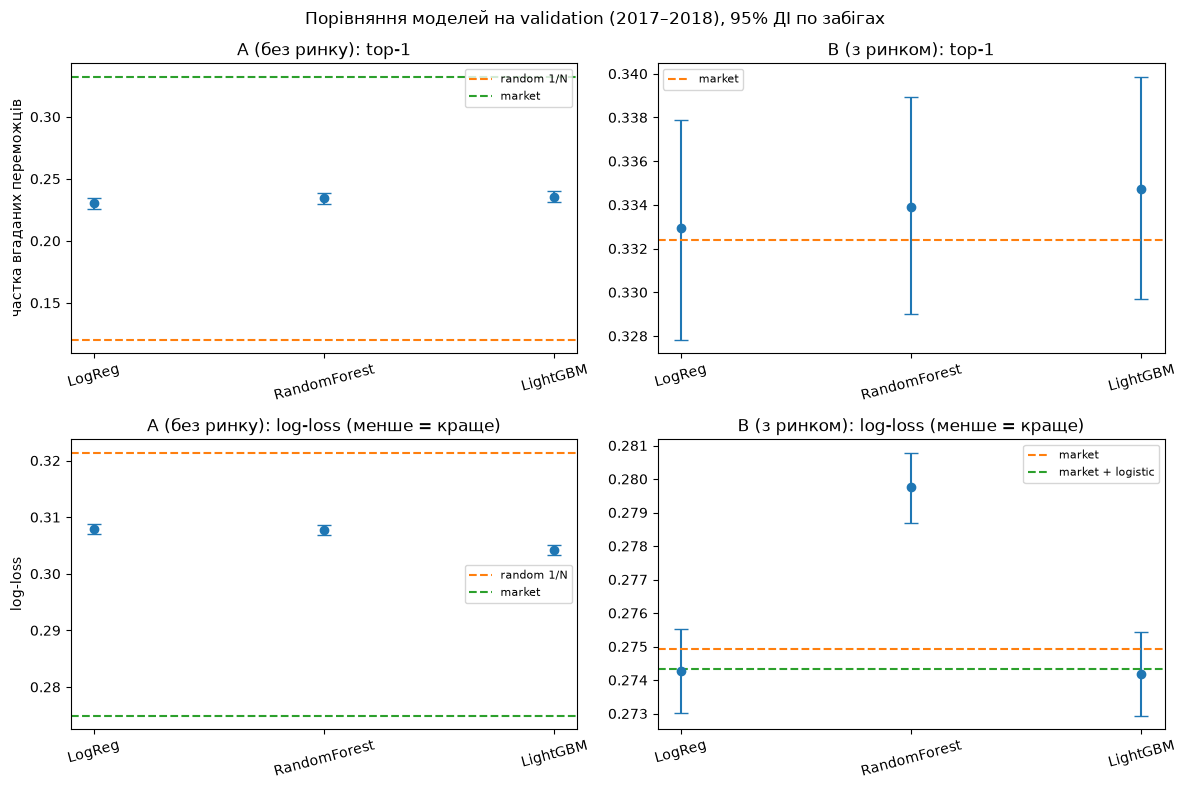

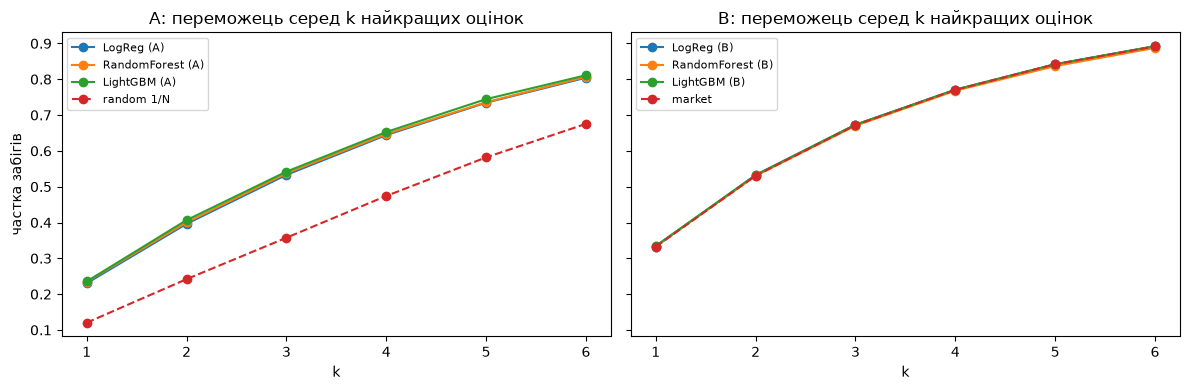

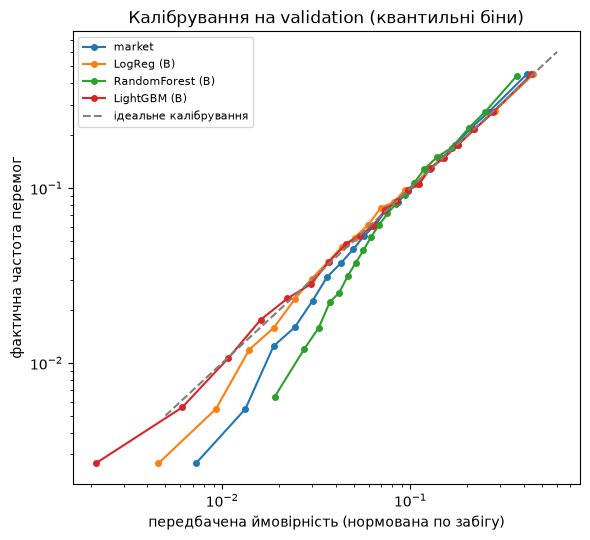

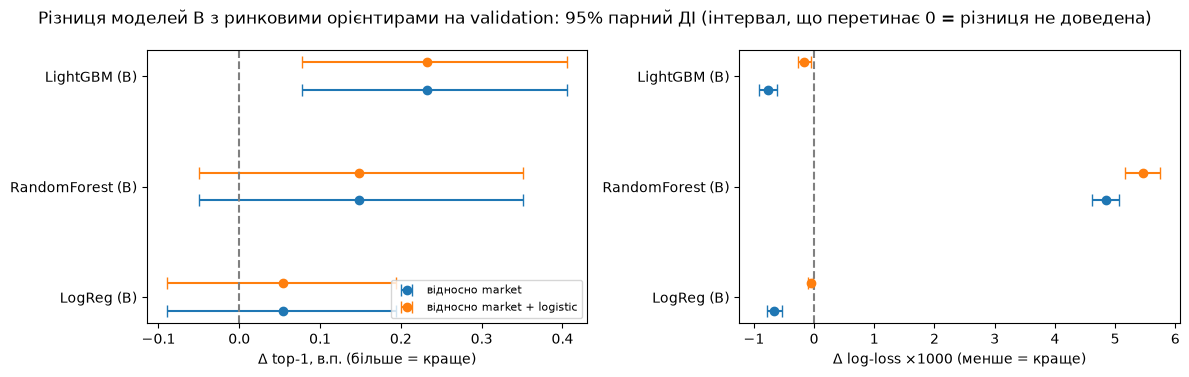

In [31]:
from horses.plots import plot_calibration, plot_hit_by_rank, plot_model_comparison, plot_paired_differences

A_names = [f"{n} (A)" for n in MODEL_NAMES]
B_names = [f"{n} (B)" for n in MODEL_NAMES]

plot_model_comparison(all_val, all_val_boot, A_names, B_names, FIG / "model_comparison.png")
plot_hit_by_rank(all_val, A_names, B_names, FIG / "hit_by_rank.png")
plot_calibration(all_val, ["market"] + B_names, FIG / "calibration.png")
plot_paired_differences(
    all_val_boot, B_names,
    "Різниця моделей B з ринковими орієнтирами на validation: 95% парний ДІ (інтервал, що перетинає 0 = різниця не доведена)",
    FIG / "diff_vs_market.png")

**Що показують графіки (validation).**

- **Експеримент A.** Усі три моделі приблизно вдвічі краще за випадковий вибір за top-1 (0,230–0,235 проти 0,120); інтервали між моделями перекриваються, тож за top-1 їх розрізнити не можна.
  За log-loss LightGBM помітно кращий (0,3042 проти 0,3079 у логістичної регресії і 0,3076 у Random Forest; інтервали не перетинаються), тобто нелінійність дає невеликий, але вимірний виграш у якості *ймовірностей*, а не у виборі переможця. До ринку при цьому далеко: log-loss 0,2749, top-1 0,332.
- **Експеримент B.** Top-1 усіх моделей (0,333–0,335) відрізняється від ринку (0,332) менш ніж на 0,3 в.п.; формально парний інтервал для LightGBM лишається над нулем (≈ +0,2 в.п.), але практично це дрібниця.
  За log-loss LogReg і LightGBM (0,2743 і 0,2742) **збігаються з ринком із перекалібруванням (0,2743)**. Випадковий ліс гірший за сирий ринок (0,2798): його ймовірності шумніші.
- **Ранжування (hit rate за рангом).** Криві моделей A лежать між випадковим вибором і ринком на всіх k; криві B збігаються з ринком.
- **Калібрування.** Ринок (синя лінія) лежить нижче діагоналі в області малих ймовірностей: коні, яким він дає ≈ 1%, насправді виграють приблизно вдвічі рідше. Це відомий зсув «фаворит–аутсайдер»: ринок завищує шанси аутсайдерів.
  Логістична регресія і LightGBM його виправляють (їхні лінії біля діагоналі), Random Forest лишається ще нижче діагоналі. Саме виправлення цього зсуву пояснює весь виграш B над сирим ринком.

### 10.5. Чутливість до складності моделі
Перевіряємо, чи не обмежує результат вибір гіперпараметрів LightGBM: змінюємо лише кількість листків за незмінних решти параметрів (експеримент B). Це аналіз чутливості, а не підбір: у фінальній порівнянні лишається заздалегідь визначена конфігурація (31 листок).

In [32]:
rows = []
for leaves in (15, 31, 63):
    pipe, cols = make_pipeline("LightGBM", "B", num_leaves=leaves)
    pipe.fit(train[cols], train[TARGET])
    r = metrics_row(f"num_leaves={leaves}", score(val, pipe.predict_proba(val[cols])[:, 1]))
    rows.append({k: r[k] for k in ("model", "top1", "log_loss", "pr_auc")})
display(pd.DataFrame(rows).round(4))

,model,top1,log_loss,pr_auc
0,num_leaves=15,0.3346,0.2741,0.3353
1,num_leaves=31,0.3347,0.2742,0.3350
2,num_leaves=63,0.3353,0.2742,0.3350


Кількість листків (15, 31, 63) майже не впливає на результат: log-loss 0,2741–0,2742 і top-1 0,3346–0,3353. Отже, потолок визначають ознаки, а не гіперпараметри, що узгоджується з відсутністю виграшу від Optuna.

### 10.6. Які ознаки важливі
Permutation importance для LightGBM з експерименту A: на скільки зростає log-loss, якщо перемішати значення однієї ознаки на 100 тис. рядків validation. Метод не залежить від того, як модель кодує ознаки, і не завищує неперервні змінні.

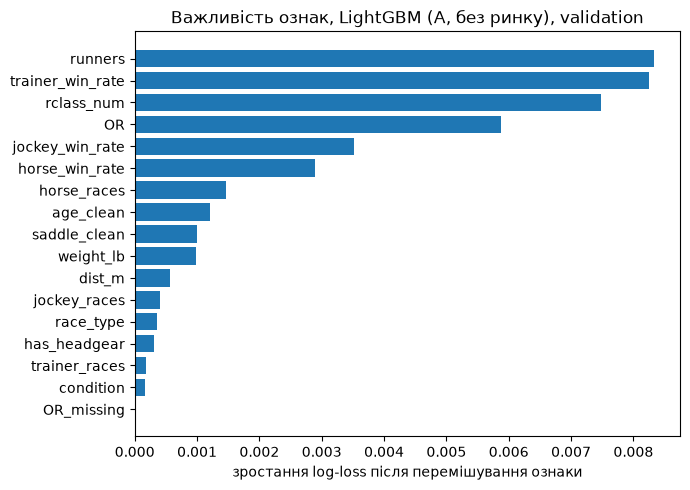

,Δ log-loss
runners,0.00833
trainer_win_rate,0.00825
rclass_num,0.00747
OR,0.00587
jockey_win_rate,0.00352
horse_win_rate,0.00289
horse_races,0.00147
age_clean,0.00121
saddle_clean,0.00100
weight_lb,0.00099


In [33]:
from horses.analysis import permutation_importances, plot_importances

pipe_A, cols_A = fitted[("A", "LightGBM")]
imp = permutation_importances(pipe_A, cols_A, val)
plot_importances(imp, FIG / "permutation_importance.png")
display(imp.sort_values(ascending=False).round(5).to_frame("Δ log-loss"))

Найважливіша ознака `runners`, але її роль переважно технічна: від розміру поля залежить загальний рівень ненормованої ймовірності кожного коня. Далі йдуть ознаки форми й класу:
`trainer_win_rate` (0,0083), `rclass_num` (0,0075), `OR` (0,0059), `jockey_win_rate` (0,0035), `horse_win_rate` (0,0029). Історичні ознаки тренера, жокея й коня разом дають значно більше, ніж базові характеристики (вік, вага, дистанція), що виправдовує їх побудову.
Метод оцінює вплив на log-loss ненормованих ймовірностей, тому для ранжування всередині забігу важливість `runners` нижча, ніж виглядає.

## 11. Аналіз помилок

Дивимося, де моделі помиляються: за розміром поля, типом забігу й упевненістю ринку, а також на конкретних найгірших промахах. Це робиться на validation, фінальний тест не використовується.

Найкращі за validation log-loss: A = LightGBM | B = LightGBM


,random 1/N,LightGBM (A),market,LightGBM (B),забігів
Розмір поля,,,,,
≤7,0.182,0.317,0.422,0.426,10309
8–10,0.113,0.230,0.327,0.328,10713
11–14,0.082,0.187,0.282,0.283,10049
15+,0.060,0.149,0.227,0.232,3413


,random 1/N,LightGBM (A),market,LightGBM (B),забігів
Упевненість ринку (макс. p),,,,,
<0.2,0.079,0.124,0.173,0.179,6159
0.2–0.3,0.107,0.179,0.261,0.263,12840
0.3–0.4,0.130,0.252,0.372,0.373,8256
>0.4,0.163,0.411,0.550,0.550,7229


,random 1/N,LightGBM (A),market,LightGBM (B),забігів
Тип забігу,,,,,
chase,0.154,0.265,0.346,0.350,3772
hurdle,0.121,0.257,0.367,0.369,5740
none,0.114,0.226,0.322,0.324,24972


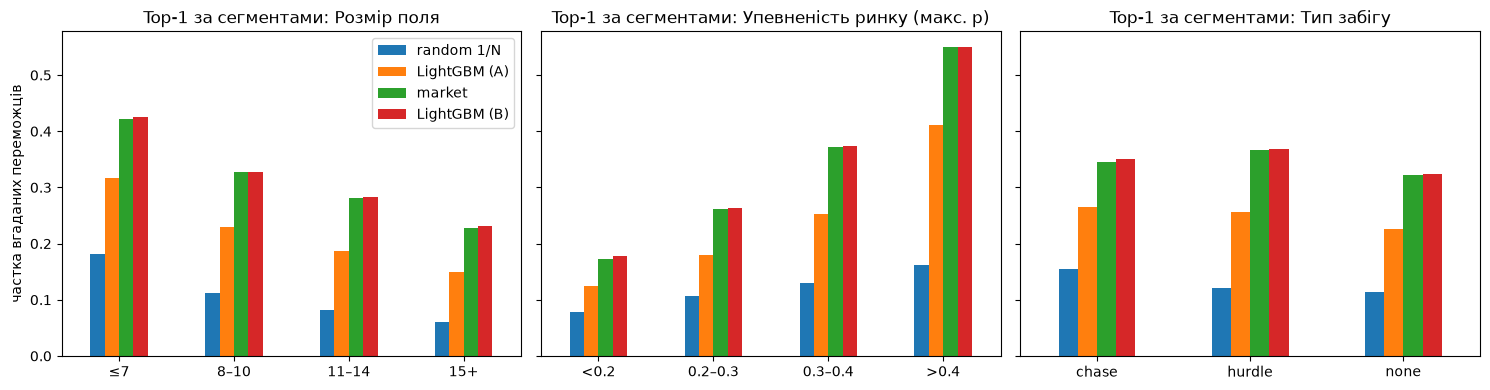

In [34]:
from horses.analysis import plot_segments, segment_frame, segment_tables

bestA = min(MODEL_NAMES, key=lambda n: metrics_row(n, all_val[f"{n} (A)"])["log_loss"])
bestB = min(MODEL_NAMES, key=lambda n: metrics_row(n, all_val[f"{n} (B)"])["log_loss"])
print("Найкращі за validation log-loss: A =", bestA, "| B =", bestB)

seg, methods = segment_frame(val, all_val, bestA, bestB)
for col, tab in segment_tables(seg, methods):
    display(tab)
plot_segments(seg, methods, FIG / "error_segments.png")

In [35]:
from horses.analysis import top_misses

display(top_misses(val, all_val[f"{bestB} (B)"], n=10))

,дата,траса,обраний кінь,p моделі,p ринку,переможець,p моделі для переможця
rid,,,,,,,
145452,18/03/22,Ludlow,Tree Of Liberty,0.927,0.917,Cap'n,0.040
138385,18/11/02,Uttoxeter,Mystical Clouds,0.895,0.893,Noble Warrior,0.089
149355,17/05/24,Southwell,Follow The Bear,0.868,0.873,Adman Sam,0.095
102657,18/08/23,Wolverhampton (AW),Rawdaa,0.856,0.872,Timespan,0.142
140182,17/10/08,Limerick (IRE),Mega Fortune,0.834,0.831,Balakani,0.109
127539,17/01/07,Newcastle,Listen To The Man,0.816,0.791,Catchamat,0.082
5513,17/01/25,Catterick,Two Taffs,0.813,0.785,Aminabad,0.117
160831,17/06/01,Wolverhampton (AW),Dutch Golden Age,0.813,0.811,Point North,0.180
165853,18/10/28,Wincanton,Rhythm Is A Dancer,0.810,0.815,Foxtrot Juliet,0.140



**Де помиляється модель без ринку (A).** У всіх сегментах A вгадує переможця у 66–77% від того, що вгадує ринок: за розміром поля (0,75 для полів ≤ 7 і 0,66 для 15+), за упевненістю ринку (0,68–0,75) і за типом забігу (0,70–0,77).
Немає сегмента, де A наближалась би до ринку чи обходила його. Відносно випадкового вибору виграш найбільший у великих полях (0,149 проти 0,060 у полях 15+, у 2,5 раза), де випадкове вгадування найгірше; у малих полях (≤ 7) модель дає 0,317 проти 0,182.
Найбільше A відстає від ринку, коли ринок невпевнений (макс. p < 0,2: 0,124 проти 0,173).

**Модель з ринком (B)** збігається з ринком у всіх сегментах із точністю до 0,6 в.п.; тобто доданий до ціни набір ознак не змінює вибір фаворита в жодній групі забігів.

**Найупевненіші промахи.** Усі десять найгірших випадків це забіги, де модель дала фавориту 0,81–0,93, і ринок був настільки ж упевнений (0,79–0,92): коротко-коефіцієнтні фаворити, які не виграли, а переможцеві модель давала 0,04–0,18.
Це не збій конкретної моделі, а неусувна випадковість: при ймовірності 0,9 фаворит програє у 10% випадків, а серед ~34 тис. забігів таких подій чимало. Причини конкретних поразок (падіння, травми, тактика) у даних відсутні, тому далі припущень ми не йдемо.


## 12. Фінальний тест (2019)

Фінальні моделі обираємо за **заздалегідь визначеним правилом**: найкращий validation log-loss серед кандидатів у кожному експерименті. Моделі лишаються навченими на train (без донавчання на validation), тест рахується один раз.
Baseline-и на тесті обчислюємо тим самим способом.

,model,top1,top1_95ci,top3,log_loss,log_loss_95ci,pr_auc,roc_auc,roi_top1,roi_95ci
0,constant (не нормована),0.1172,[0.1125; 0.1223],0.3574,0.3257,[0.3245; 0.3270],0.1003,0.5000,-0.2609,[-0.3046; -0.2163]
1,random 1/N,0.1172,[0.1125; 0.1223],0.3574,0.3172,[0.3161; 0.3184],0.1516,0.6166,-0.2609,[-0.3046; -0.2163]
2,market,0.3424,[0.3351; 0.3491],0.6712,0.2703,[0.2688; 0.2720],0.3362,0.7944,-0.0850,[-0.1076; -0.0657]
3,market + logistic,0.3424,[0.3351; 0.3491],0.6712,0.2697,[0.2681; 0.2715],0.3368,0.7946,-0.0850,[-0.1076; -0.0657]
4,LightGBM (A),0.2331,[0.2264; 0.2396],0.5378,0.3008,[0.2995; 0.3021],0.2260,0.7032,-0.1494,[-0.1811; -0.1174]
5,LightGBM (B),0.3415,[0.3342; 0.3484],0.6717,0.2696,[0.2679; 0.2714],0.3365,0.7947,-0.0851,[-0.1066; -0.0658]


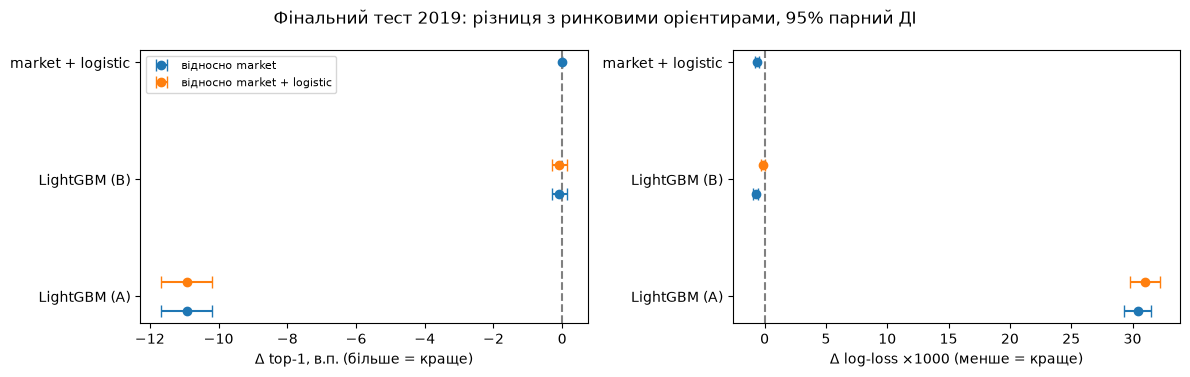

In [36]:
final = {"A": bestA, "B": bestB}
test_scores = baseline_scores(test, train_rate, lr_mkt)
for exp in ("A", "B"):
    pipe, cols = fitted[(exp, final[exp])]
    test_scores[f"{final[exp]} ({exp})"] = score(test, pipe.predict_proba(test[cols])[:, 1])

test_boot = bootstrap(test_scores)
test_table = summary_table(test_scores, test_boot)
display(test_table)

fA, fB = f"{final['A']} (A)", f"{final['B']} (B)"
plot_paired_differences(
    test_boot, [fA, fB, "market + logistic"],
    "Фінальний тест 2019: різниця з ринковими орієнтирами, 95% парний ДІ",
    FIG / "test_diff_vs_market.png")

**Про тест.** У 2019 ринок вгадує переможця частіше, ніж на validation (0,342 проти 0,332), тобто це «легший» для фаворитів рік. Саме тому baseline-и на тесті обчислені окремо, а оцінки моделей ніколи не порівнюються з числами validation напряму.
Співвідношення збереглося: модель без ринку (A) далека від ринку (0,233 проти 0,342), модель з ринком (B) від нього практично не відрізняється (0,3415 проти 0,3424).

## 13. Висновки та обмеження

In [37]:
from IPython.display import Markdown

from horses.reporting import line


def m(scs, k, key):
    return metrics_row(k, scs[k])[key]


rnd_t1, mkt_t1 = m(test_scores, "random 1/N", "top1"), m(test_scores, "market", "top1")
t1A = m(test_scores, fA, "top1")
t1B = m(test_scores, fB, "top1")
roiA, roiB, roiM = (m(test_scores, k, "roi_top1") for k in (fA, fB, "market"))

estA, loA, hiA = paired(test_boot, fA, "random 1/N", "top1")
sigA = ("несуть статистично значущий сигнал понад випадковість" if loA > 0
        else "не відрізняються від випадкового вибору")
estB, loB, hiB = paired(test_boot, fB, "market", "log_loss")
estR, loR, hiR = paired(test_boot, fB, "market + logistic", "log_loss")
estC, loC, hiC = paired(test_boot, "market + logistic", "market", "log_loss")
crit = "**виконано**" if hiR < 0 else "**не виконано**"
if hiR < 0:
    expl = "Модель B дає покращення log-loss і понад ринок із перекалібруванням."
elif loR > 0:
    expl = "Модель B гірша за ринок із перекалібруванням."
elif hiB < 0:
    expl = ("Покращення log-loss моделі B відносно сирого ринку пояснюється **виправленням систематичного зсуву ринкових ймовірностей** "
            "(його дає й проста логістична регресія на самій ціні): відносно ринку з перекалібруванням різниця не відрізняється від нуля.")
else:
    expl = "Модель B не відрізняється ні від сирого ринку, ні від ринку з перекалібруванням."

txt = f"""
### Головні результати (фінальний тест 2019, {len(test_scores['market']['rt']):,} забігів)

**Експеримент A: без ринкової ціни.** Найкраща за validation модель — {fA}. Вона вгадує переможця у **{t1A:.1%}** забігів
проти {rnd_t1:.1%} при випадковому виборі (у {t1A / rnd_t1:.1f} раза частіше); ринок вгадує {mkt_t1:.1%}.
Характеристики коня й забігу та історія форми {sigA} (Δ top-1 відносно випадкового вибору: {estA * 100:+.1f} в.п. [{loA * 100:+.1f}; {hiA * 100:+.1f}]).

{line(test_boot, fA, 'market', f'{fA} проти ринку')}

**Експеримент B: з ринковою ціною.** Найкраща за validation модель — {fB}, top-1 **{t1B:.1%}** (ринок {mkt_t1:.1%}).

{line(test_boot, fB, 'market', f'{fB} проти сирого ринку')}
{line(test_boot, fB, 'market + logistic', f'{fB} проти ринку з перекалібруванням')}
{line(test_boot, 'market + logistic', 'market', 'ринок з перекалібруванням проти сирого ринку')}

**Критерій з розділу 1** (95% ДІ різниці log-loss повністю в області покращення відносно ринку з перекалібруванням): {crit}
(Δ log-loss = {estR * 1000:+.2f} ×10⁻³ [{loR * 1000:+.2f}; {hiR * 1000:+.2f}]). {expl}

**Прибуток плоскої ставки на фаворита моделі** (за коефіцієнтом 1/`decimalPrice`): ринковий фаворит {roiM:+.1%}, {fA} {roiA:+.1%}, {fB} {roiB:+.1%} на ставку.
Усі значення від'ємні: стратегія «ставити на фаворита» програє приблизно на розмір маржі букмекера; довірчі інтервали ROI подано в таблиці вище.
"""
display(Markdown(txt))


### Головні результати (фінальний тест 2019, 17,206 забігів)

**Експеримент A: без ринкової ціни.** Найкраща за validation модель — LightGBM (A). Вона вгадує переможця у **23.3%** забігів
проти 11.7% при випадковому виборі (у 2.0 раза частіше); ринок вгадує 34.2%.
Характеристики коня й забігу та історія форми несуть статистично значущий сигнал понад випадковість (Δ top-1 відносно випадкового вибору: +11.6 в.п. [+10.8; +12.4]).

- LightGBM (A) проти ринку: log-loss: Δ = +30.42 ×10⁻³ [+29.28; +31.49] — **гірше за ринок**; top-1: Δ = -10.91 в.п. [-11.69; -10.18] — **гірше за ринок**

**Експеримент B: з ринковою ціною.** Найкраща за validation модель — LightGBM (B), top-1 **34.2%** (ринок 34.2%).

- LightGBM (B) проти сирого ринку: log-loss: Δ = -0.73 ×10⁻³ [-0.94; -0.50] — **краще за ринок**; top-1: Δ = -0.08 в.п. [-0.30; +0.15] — статистично **не відрізняється від ринку**
- LightGBM (B) проти ринку з перекалібруванням: log-loss: Δ = -0.12 ×10⁻³ [-0.26; +0.03] — статистично **не відрізняється від ринку**; top-1: Δ = -0.08 в.п. [-0.30; +0.15] — статистично **не відрізняється від ринку**
- ринок з перекалібруванням проти сирого ринку: log-loss: Δ = -0.60 ×10⁻³ [-0.75; -0.46] — **краще за ринок**; top-1: Δ = +0.00 в.п. [+0.00; +0.00] — статистично **не відрізняється від ринку**

**Критерій з розділу 1** (95% ДІ різниці log-loss повністю в області покращення відносно ринку з перекалібруванням): **не виконано**
(Δ log-loss = -0.12 ×10⁻³ [-0.26; +0.03]). Покращення log-loss моделі B відносно сирого ринку пояснюється **виправленням систематичного зсуву ринкових ймовірностей** (його дає й проста логістична регресія на самій ціні): відносно ринку з перекалібруванням різниця не відрізняється від нуля.

**Прибуток плоскої ставки на фаворита моделі** (за коефіцієнтом 1/`decimalPrice`): ринковий фаворит -8.5%, LightGBM (A) -14.9%, LightGBM (B) -8.5% на ставку.
Усі значення від'ємні: стратегія «ставити на фаворита» програє приблизно на розмір маржі букмекера; довірчі інтервали ROI подано в таблиці вище.


### Обмеження

- **Ринкова ціна** — це ціна на старті. Експеримент B показує внесок ознак понад неї, але не є готовою стратегією ставок: не враховано комісії, ліміти ставок, зміну коефіцієнтів до старту.
- **Ознаки прості.** Немає останніх N виступів, відпочинку між стартами, спеціалізації за дистанцією, покриттям і трасою, родоводу; експеримент A, ймовірно, занижує те, що можна витягнути з публічних даних.
- **Ідентифікатори** коня, жокея й тренера — імена; можливі збіги.
- **Дрейф.** Базовий рівень і розмір полів змінюються в часі. Моделі навчені на 2005–2016 і не донавчені на 2017–2018 перед тестом.
- **Статистична невизначеність.** Тест — один рік (≈ 17 тис. забігів). Інтервали враховують вибірковий шум по забігах, але не враховують вибір гіперпараметрів, дрейф між роками чи залежність між сусідніми забігами одного дня.
- **Обсяг даних.** 1 386 забігів без коней і 655 неоднозначних (мертві гонки та забіги без переможця) виключено; 2020 рік виключено (неповний, інша схема).
- **ROI** розрахований за коефіцієнтом 1/`decimalPrice` і має важкі хвости; навіть вузький інтервал не гарантує практичної стратегії.
- **Множинні порівняння.** Порівняно кілька моделей і метрик; окрема «значуща» різниця могла б виникнути випадково, тому оцінюємо узгодженість усіх метрик, а не одну.

## 14. Відтворюваність

**Середовище.** Python 3.12–3.14, бібліотеки: `pandas`, `numpy`, `pyarrow`, `matplotlib`, `scikit-learn`, `lightgbm`. Версії фіксуються в `requirements.txt` командою `pip freeze > requirements.txt`; версії основних бібліотек також друкуються нижче.

**Запуск.**
1. Завантажити дані: `kaggle datasets download -d hwaitt/horse-racing` (потрібен API-токен Kaggle) або вручну зі сторінки датасету; розпакувати CSV в `data/raw/`.
2. `python scripts/merge_data.py` — з'єднує файли й записує `data/merged.parquet`.
3. Виконати `notebooks/horses.ipynb` зверху вниз. Усі випадкові процеси використовують `SEED = 42`.

**Джерело даних.** Kaggle, `hwaitt/horse-racing` (автор датасету: hwaitt).

In [38]:
import sklearn, lightgbm
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| lightgbm", lightgbm.__version__, "| SEED =", SEED)

python 3.14.7 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | lightgbm 4.7.0 | SEED = 42


## Розкриття використання штучного інтелекту

- **Інструмент:** Claude (Anthropic).
- **Для чого використано:** консультація по написанню коду для огляду даних, baseline-ів, пайплайнів і графіків; редагування тексту для пояснення кожного кроку.
- **Що зроблено самостійно:** вибір теми й датасету, постановка питання, написання коду, перевірка результатів, вибір рішень. 
- **Що знайшов ШІ, а що перевірено на даних:** помилку аудиту витоку було виявлено й виправлено, див. розділ 3
- **Інші інструменти ШІ:** 
- **Як перевірено правильність:** тест на витік історичних ознак (розділ 9), перевірка `metric` і `margin` на даних (розділ 3.1), порівняння з baseline-ами, bootstrap-інтервали.